# Laboratorio 2. Pronóstico de precios bursátiles con RNN, LSTM y GRU

**Empresa:** Apple Inc. (AAPL) · **Lenguaje:** Python · **Biblioteca de aprendizaje profundo:** PyTorch.

Este trabajo examina una pregunta concreta: ¿una red neuronal recurrente puede anticipar el cierre bursátil del día siguiente con mayor precisión que usar simplemente el último cierre observado? Para responderla se comparan tres arquitecturas, tanto con el precio de cierre por sí solo como con un conjunto de variables de mercado.

El ejercicio es académico. Las estimaciones no constituyen recomendaciones de inversión.

El cuaderno parte de los datos históricos, construye ventanas y compara predicciones con sus valores reales. El modelo se escoge usando validación; la prueba final se reserva para comprobar si esa elección funciona también en fechas posteriores. Las cifras del informe se calculan durante la ejecución, no se copian a mano.

In [1]:
import sys
import subprocess

# Instalar las bibliotecas necesarias para obtener datos y dibujar las gráficas.
subprocess.check_call([
    sys.executable, "-m", "pip", "-q", "install",
    "yfinance", "mplfinance", "statsmodels",
])


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


0

In [2]:
import copy
import os
import random

import matplotlib.pyplot as plt
import mplfinance as mpf
import numpy as np
import pandas as pd
import torch
import yfinance as yf

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_acf
from torch import nn
from torch.utils.data import DataLoader, Dataset

torch.set_num_threads(min(2, os.cpu_count() or 2))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Versión de PyTorch:", torch.__version__, "Dispositivo:", DEVICE)

Versión de PyTorch: 2.14.1+cpu Dispositivo: cpu


## 1. Obtención y conservación de los datos

Se utilizan cotizaciones diarias de Apple descargadas desde Yahoo Finance por medio de `yfinance`. El archivo CSV conserva la misma muestra entre ejecuciones, algo importante porque la fuente puede actualizar o corregir su información histórica.

Se incluyen fecha, apertura, máximo, mínimo, cierre y volumen. Con `auto_adjust=True`, los precios OHLC se ajustan por operaciones corporativas según la información suministrada por Yahoo Finance. Al ejecutar esta sección se informa el periodo disponible y se muestran las observaciones más recientes.

In [3]:
os.makedirs("data", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

csv_path = "data/AAPL_ohlcv.csv"
price_columns = ["Open", "High", "Low", "Close", "Volume"]

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path, index_col=0, parse_dates=True)
else:
    df = yf.download("AAPL", period="7y", auto_adjust=True, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df[price_columns].dropna()
    df.to_csv(csv_path)

df.index = pd.to_datetime(df.index, utc=True).tz_localize(None)
df = df.sort_index().dropna()

assert len(df) > 252 * 5, "No hay suficientes datos históricos diarios"
print(df.shape, df.index.min(), df.index.max())
display(df.tail())

(1758, 5) 2019-10-22 00:00:00 2026-10-20 00:00:00


,Open,High,Low,Close,Volume
Date,,,,,
2026-10-14,344.609985,347.089996,341.720001,342.959991,50061100
2026-10-15,346.950012,347.850006,341.600006,342.000000,39767300
2026-10-16,346.089996,347.820007,340.459991,343.459991,59946400
2026-10-19,340.779999,346.000000,340.119995,342.940002,34573200
2026-10-20,339.859985,343.059998,338.700012,339.500000,35851400


## 2. Preparación de variables y separación temporal

La predicción se basa exclusivamente en información disponible **antes** del cierre que se intenta estimar. Para enriquecer las entradas se calculan dos medias móviles (20 y 50 sesiones), volatilidad de los rendimientos de 20 sesiones y amplitud intradía relativa.

Se respeta el orden de las fechas: aproximadamente 70 % de los datos se usa para entrenamiento, 15 % para validación y el 15 % restante para prueba. Los valores necesarios para estandarizar las variables se calculan solo con el periodo de entrenamiento. De este modo, los datos posteriores no influyen en el ajuste.

Las figuras siguientes permiten ubicar los periodos y observar tanto las velas bursátiles como las medias móviles.

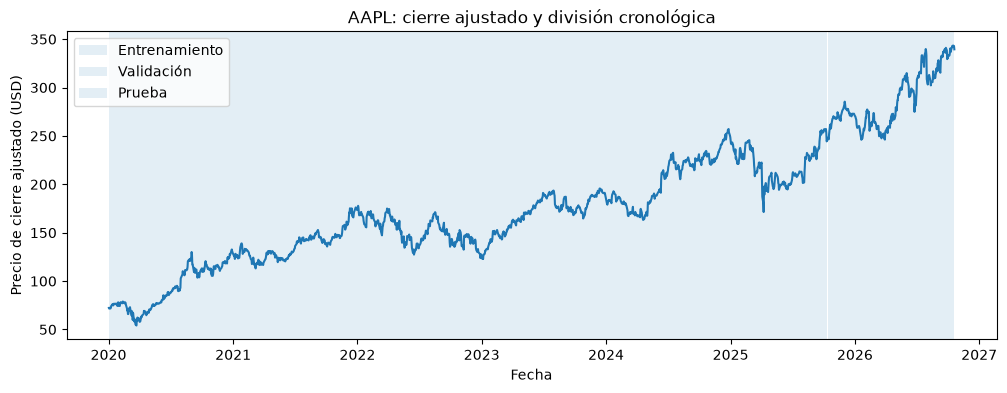

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


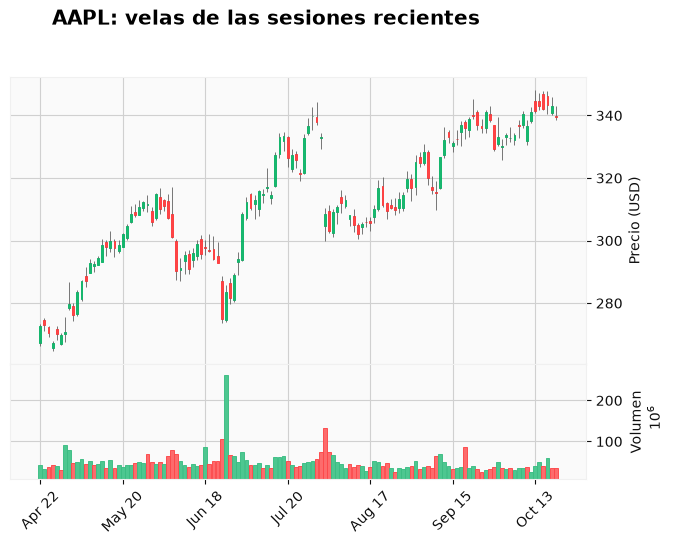

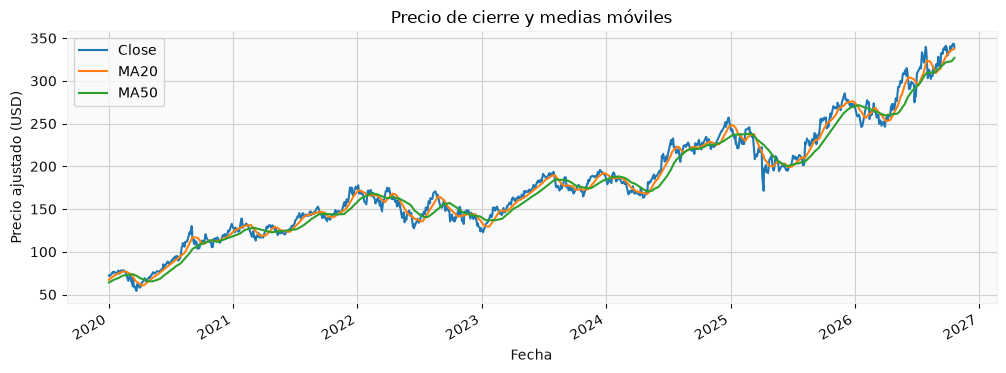

In [4]:
df["MA20"] = df.Close.rolling(20).mean()
df["MA50"] = df.Close.rolling(50).mean()
df["VOL20"] = df.Close.pct_change().rolling(20).std()
df["Range"] = (df.High - df.Low) / df.Close
df = df.dropna().copy()

n = len(df)
a = int(n * 0.7)
b = int(n * 0.85)
LOOKBACK = 60

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df.Close)
ax.axvspan(df.index[0], df.index[a - 1], alpha=0.12, label="Entrenamiento")
ax.axvspan(df.index[a], df.index[b - 1], alpha=0.12, label="Validación")
ax.axvspan(df.index[b], df.index[-1], alpha=0.12, label="Prueba")
ax.set_title("AAPL: cierre ajustado y división cronológica")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio de cierre ajustado (USD)")
ax.legend()
plt.show()

mpf.plot(
    df[["Open", "High", "Low", "Close", "Volume"]].tail(126),
    type="candle",
    volume=True,
    style="yahoo",
    title="AAPL: velas de las sesiones recientes",
    ylabel="Precio (USD)",
    ylabel_lower="Volumen",
)

ax = df[["Close", "MA20", "MA50"]].plot(
    figsize=(12, 4), title="Precio de cierre y medias móviles"
)
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio ajustado (USD)")
plt.show()

## 3. Ventanas de observación y métodos de referencia

Para estimar el cierre de una sesión, el modelo recibe las **60 sesiones anteriores** (ventana de entrada). El cierre que debe predecir queda fuera de esa ventana. Durante la evaluación se permite usar precios anteriores al inicio del periodo de prueba como contexto, pero nunca el valor futuro que se busca predecir.

Hay dos referencias que conviene calcular antes de mirar los resultados de las redes: el cierre inmediatamente anterior y el promedio de los 20 cierres previos. Son comparaciones exigentes porque no necesitan entrenamiento. De hecho, en la prueba final del experimento el último cierre fue más preciso que la red seleccionada.

Las métricas son MAE (error absoluto medio), RMSE (raíz del error cuadrático medio) y MAPE (error porcentual absoluto medio). Para evitar dividir entre cero, MAPE utiliza un denominador mínimo.

In [5]:
def windows(cols):
    """Crea ventanas de historial y sus objetivos, sin incluir el día a predecir."""
    sx = StandardScaler().fit(df.iloc[:a][cols])
    sy = StandardScaler().fit(df.iloc[:a][["Close"]])

    X = sx.transform(df[cols]).astype("float32")
    y = sy.transform(df[["Close"]]).astype("float32").ravel()

    xx, yy, ids = [], [], []
    for t in range(LOOKBACK, len(df)):
        xx.append(X[t - LOOKBACK:t])
        yy.append(y[t])
        ids.append(t)

    return np.array(xx), np.array(yy), np.array(ids), sy, sx


class SlidingWindowDataset(Dataset):
    """Entrega una secuencia anterior y el cierre que corresponde predecir."""

    def __init__(self, X, y):
        self.X = torch.as_tensor(X, dtype=torch.float32)
        self.y = torch.as_tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


def baselines(ids):
    """Dos pronósticos de referencia que no requieren entrenamiento."""
    actual = df.Close.to_numpy()
    last = actual[ids - 1]
    ma = np.array([actual[t - 20:t].mean() for t in ids])
    return last, ma


def metrics(y, p):
    """MAE y RMSE en dólares; MAPE en porcentaje."""
    return {
        "MAE": float(mean_absolute_error(y, p)),
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "MAPE%": float(np.mean(np.abs((y - p) / np.maximum(np.abs(y), 1e-8))) * 100),
    }


test_indices = np.arange(b, n)
test_close = df.Close.to_numpy()[test_indices]
last_close, _ = baselines(test_indices)
print("Referencia: último cierre observado", metrics(test_close, last_close))

Referencia: último cierre observado {'MAE': 3.138942258367278, 'RMSE': 4.439534442183769, 'MAPE%': 1.0897541452501074}


## 4. Arquitecturas recurrentes en PyTorch

Se comparan **RNN, LSTM y GRU**. En cada caso, la capa recurrente procesa la secuencia de observaciones y una capa lineal convierte su estado final en una única predicción: el cierre del siguiente día bursátil.

Las tres arquitecturas utilizan las mismas particiones temporales y el mismo objetivo, lo que permite comparar sus errores con un criterio común. El entrenamiento utiliza Adam, parada anticipada según la pérdida de validación, ajuste de la tasa de aprendizaje y almacenamiento de los mejores pesos.

In [6]:
class ForecastNet(nn.Module):
    def __init__(self, kind, n_features, hidden=32):
        super().__init__()

        recurrent_layers = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
        self.recurrent = recurrent_layers[kind](
            n_features, hidden, batch_first=True
        )
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        output, _ = self.recurrent(x)
        return self.head(output[:, -1, :]).squeeze(-1)


def train(kind, cols, epochs=35, patience=8):
    """Entrena una configuración y devuelve sus métricas y predicciones."""
    X, y, ids, sy, sx = windows(cols)
    tr = ids < a
    va = (ids >= a) & (ids < b)
    te = ids >= b

    loader = DataLoader(
        SlidingWindowDataset(X[tr], y[tr]),
        batch_size=64,
        shuffle=True,
    )

    net = ForecastNet(kind, len(cols)).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=0.001)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=0.5, patience=3
    )
    lossfn = nn.MSELoss()
    best = float("inf")
    wait = 0
    history = []
    best_state = None

    for epoch in range(epochs):
        net.train()
        total = 0

        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = lossfn(net(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)

        net.eval()
        with torch.no_grad():
            vl = lossfn(
                net(torch.tensor(X[va], device=DEVICE)),
                torch.tensor(y[va], device=DEVICE),
            ).item()

        scheduler.step(vl)
        with torch.no_grad():
            val_scaled = net(torch.tensor(X[va], device=DEVICE)).cpu().numpy()

        val_pred = sy.inverse_transform(val_scaled.reshape(-1, 1)).ravel()
        val_rmse = float(
            np.sqrt(np.mean((val_pred - df.Close.to_numpy()[ids[va]]) ** 2))
        )
        history.append((total / tr.sum(), vl, val_rmse))

        # La mejor época se define con validación, no con la prueba final.
        if vl < best - 1e-6:
            best = vl
            wait = 0
            best_state = copy.deepcopy(net.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break

    net.load_state_dict(best_state)
    name = f"{kind}_{len(cols)}features_L{LOOKBACK}"

    checkpoint = {
        "state_dict": best_state,
        "features": cols,
        "kind": kind,
        "lookback": LOOKBACK,
        "scaler_x_mean": sx.mean_.tolist(),
        "scaler_x_scale": sx.scale_.tolist(),
        "scaler_y_mean": sy.mean_.tolist(),
        "scaler_y_scale": sy.scale_.tolist(),
    }
    torch.save(checkpoint, f"checkpoints/{name}.pt")

    net.eval()
    with torch.no_grad():
        pred = net(torch.tensor(X[te], device=DEVICE)).cpu().numpy()
    prediction = sy.inverse_transform(pred.reshape(-1, 1)).ravel()
    actual = df.Close.to_numpy()[ids[te]]

    with torch.no_grad():
        vp = net(torch.tensor(X[va], device=DEVICE)).cpu().numpy()
    validation_pred = sy.inverse_transform(vp.reshape(-1, 1)).ravel()
    validation_actual = df.Close.to_numpy()[ids[va]]

    return (
        name,
        metrics(actual, prediction),
        history,
        ids[te],
        actual,
        prediction,
        metrics(validation_actual, validation_pred),
    )

## 5. Experimentos: una variable frente a varias

Cada arquitectura se entrena con dos configuraciones: **univariada**, que utiliza únicamente el cierre, y **multivariada**, que utiliza cierre, volumen, dos medias móviles, volatilidad y amplitud intradía. Esto genera seis experimentos principales con 60 sesiones de historial.

Las métricas se guardan separadamente para validación y prueba. La elección del modelo recurrente se realiza con el **RMSE de validación**, no con el error de prueba: consultar la prueba para elegir el modelo introduciría sesgo en la comparación final.

## 6. Efecto de la longitud de la ventana

Además de la ventana habitual de 60 sesiones, se entrena una LSTM univariada con ventanas de **30 y 90 sesiones**. La comparación permite observar si disponer de más historial ayuda o perjudica al modelo en este conjunto de datos.

El periodo de validación y los parámetros generales de entrenamiento se mantienen. Después se restablece la ventana de 60 sesiones para los procedimientos que la requieren. Esta prueba es limitada y no equivale a una búsqueda exhaustiva de hiperparámetros.

In [7]:
experiments = []
feature_sets = [
    ["Close"],
    ["Close", "Volume", "MA20", "MA50", "VOL20", "Range"],
]

for cols in feature_sets:
    for kind in ["RNN", "LSTM", "GRU"]:
        result = train(kind, cols)
        experiments.append(result)
        print(result[0], result[1])

for alternate_lookback in [30, 90]:
    LOOKBACK = alternate_lookback
    result = train("LSTM", ["Close"])
    experiments.append(result)
    print("Comparación de ventana histórica:", alternate_lookback, result[6])

LOOKBACK = 60

rows = []
for experiment in experiments:
    model, test_scores, _, _, _, _, validation_scores = experiment
    row = {"model": model}
    row.update({"test_" + key: value for key, value in test_scores.items()})
    row.update({"validation_" + key: value for key, value in validation_scores.items()})
    rows.append(row)

results = pd.DataFrame(rows)
display(
    results.sort_values("validation_RMSE").rename(
        columns={
            "model": "Modelo",
            "test_MAE": "Prueba MAE",
            "test_RMSE": "Prueba RMSE",
            "test_MAPE%": "Prueba MAPE %",
            "validation_MAE": "Validación MAE",
            "validation_RMSE": "Validación RMSE",
            "validation_MAPE%": "Validación MAPE %",
        }
    )
)

ids = experiments[0][3]
actual = experiments[0][4]
last, ma = baselines(ids)
baseline_results = pd.DataFrame([
    {"model": "Último cierre observado", **metrics(actual, last)},
    {"model": "Media móvil de 20 días", **metrics(actual, ma)},
])
display(baseline_results)
assert len(ids) == len(actual) == len(last) == len(ma)

os.makedirs("reports", exist_ok=True)
results.rename(
    columns={
        "model": "modelo",
        "test_MAE": "prueba_MAE",
        "test_RMSE": "prueba_RMSE",
        "test_MAPE%": "prueba_MAPE%",
        "validation_MAE": "validacion_MAE",
        "validation_RMSE": "validacion_RMSE",
        "validation_MAPE%": "validacion_MAPE%",
    }
).to_csv("reports/model_metrics.csv", index=False)
baseline_results.rename(columns={"model": "modelo"}).to_csv(
    "reports/baseline_metrics.csv", index=False
)

RNN_1features_L60 {'MAE': 29.11812333281402, 'RMSE': 34.91627606010989, 'MAPE%': 9.577759121894251}


LSTM_1features_L60 {'MAE': 42.05851840601821, 'RMSE': 48.8557290387785, 'MAPE%': 13.925932756205682}


GRU_1features_L60 {'MAE': 25.769861065460088, 'RMSE': 31.38815077572379, 'MAPE%': 8.449200594569142}


RNN_6features_L60 {'MAE': 27.012553946053472, 'RMSE': 33.31448642983732, 'MAPE%': 8.8325165702342}


LSTM_6features_L60 {'MAE': 44.729937304782496, 'RMSE': 51.36343272510238, 'MAPE%': 14.853378451170975}


GRU_6features_L60 {'MAE': 27.71447617348994, 'RMSE': 34.229327128810475, 'MAPE%': 9.06009756700363}


Comparación de ventana histórica: 30 {'MAE': 5.9496623277664185, 'RMSE': 7.973701391006441, 'MAPE%': 2.6460409262410822}


Comparación de ventana histórica: 90 {'MAE': 5.885747313499451, 'RMSE': 7.965542091736976, 'MAPE%': 2.61950440874689}


,Modelo,Prueba MAE,Prueba RMSE,Prueba MAPE %,Validación MAE,Validación RMSE,Validación MAPE %
3,RNN_6features_L60,27.012554,33.314486,8.832517,4.221092,5.673365,1.909148
2,GRU_1features_L60,25.769861,31.388151,8.449201,4.253885,5.830635,1.917947
0,RNN_1features_L60,29.118123,34.916276,9.577759,4.666398,6.305029,2.109586
5,GRU_6features_L60,27.714476,34.229327,9.060098,5.012363,6.851715,2.276656
7,LSTM_1features_L90,39.966298,46.542318,13.226179,5.885747,7.965542,2.619504
6,LSTM_1features_L30,39.738637,46.471911,13.138030,5.949662,7.973701,2.646041
1,LSTM_1features_L60,42.058518,48.855729,13.925933,6.089077,8.160303,2.701519
4,LSTM_6features_L60,44.729937,51.363433,14.853378,6.996157,9.073387,3.114601


,model,MAE,RMSE,MAPE%
0,Último cierre observado,3.138942,4.439534,1.089754
1,Media móvil de 20 días,9.878036,11.759159,3.400129


## 7. Curvas de aprendizaje, predicciones y residuos

Se grafican las pérdidas de entrenamiento y validación, así como el RMSE de validación por época. Para el modelo elegido se contrasta el cierre real con el estimado sobre el periodo de prueba, que permaneció reservado.

Después se analizan los residuos (valor real menos predicción). Su evolución, histograma y autocorrelación ayudan a detectar errores persistentes o agrupados. La franja alrededor de la predicción usa la dispersión de esos residuos: **no es un intervalo de confianza calibrado**. Por eso no se interpreta como una probabilidad de acierto.

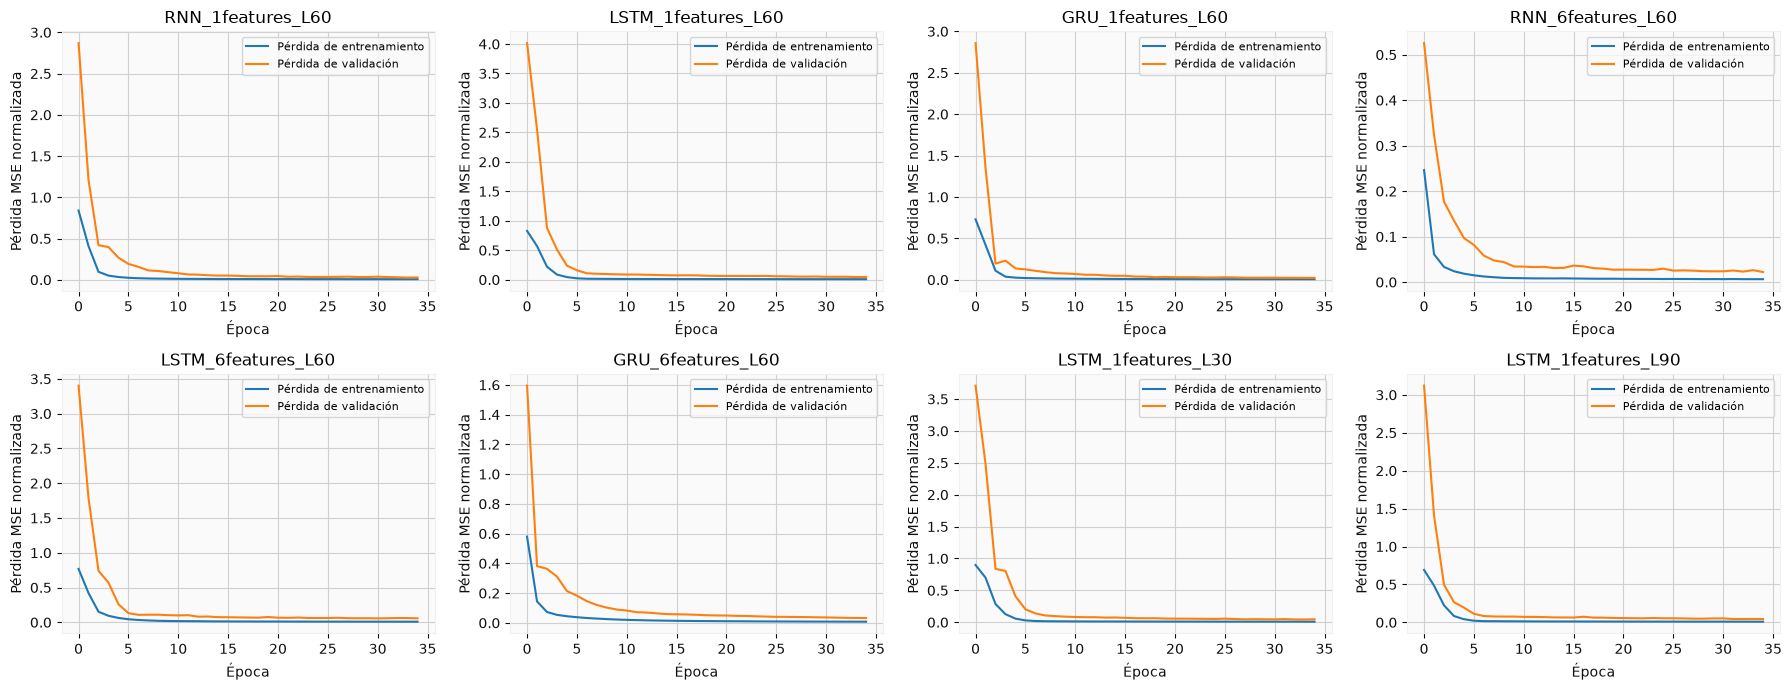

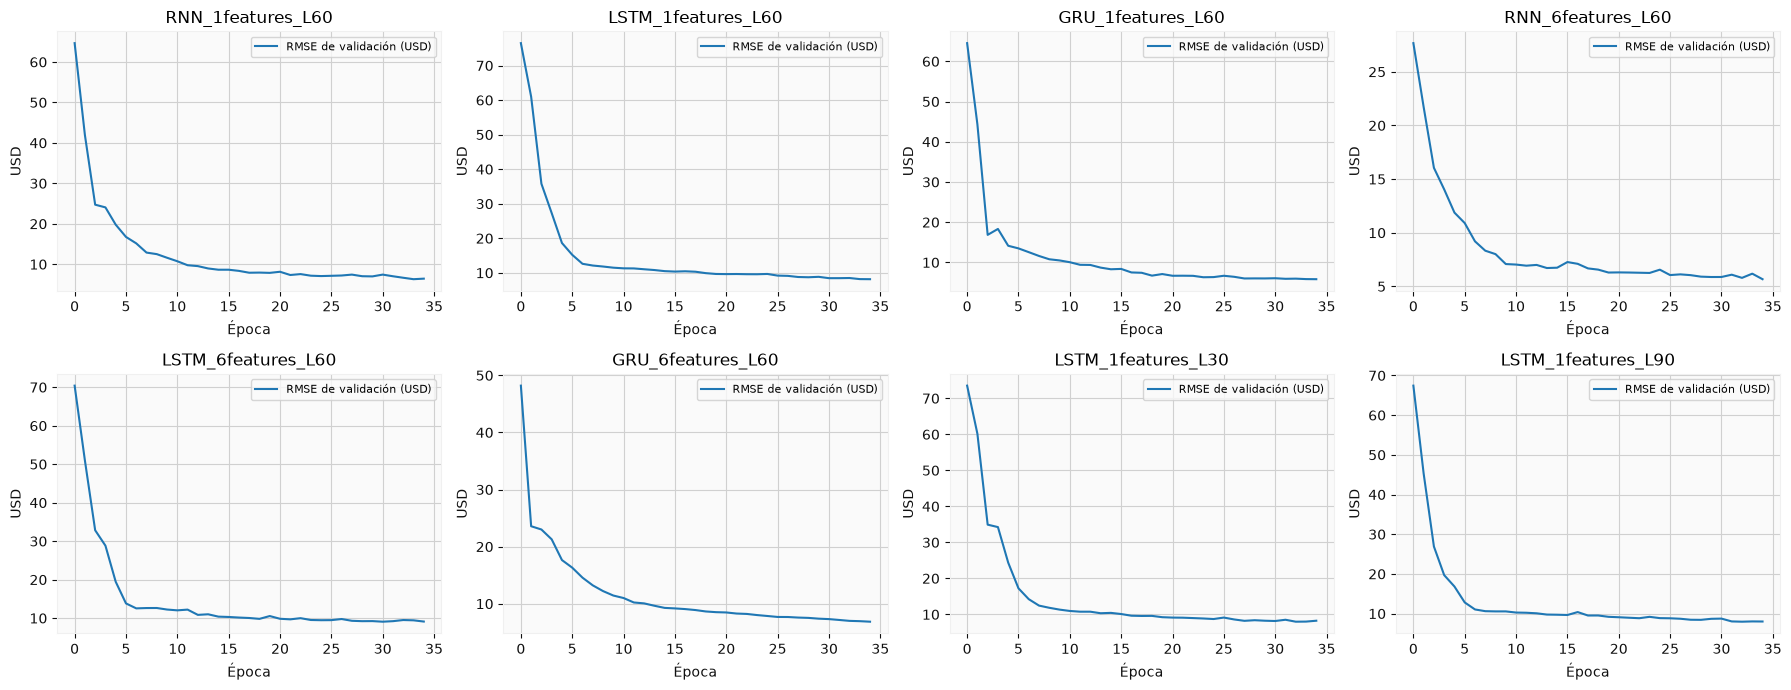

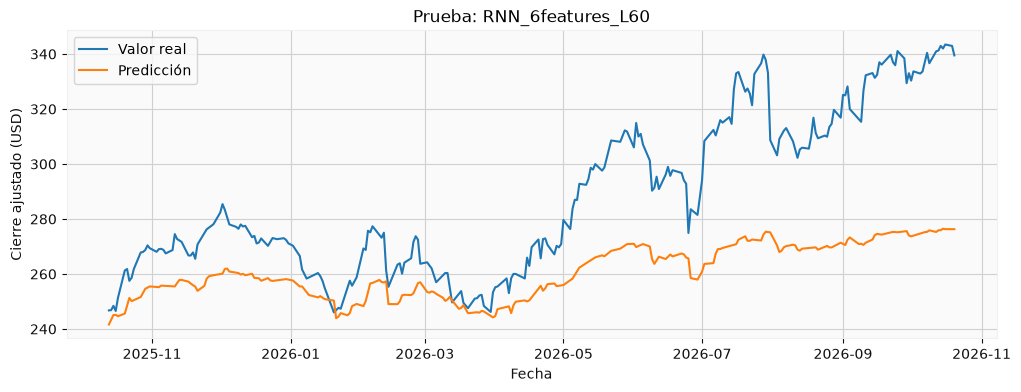

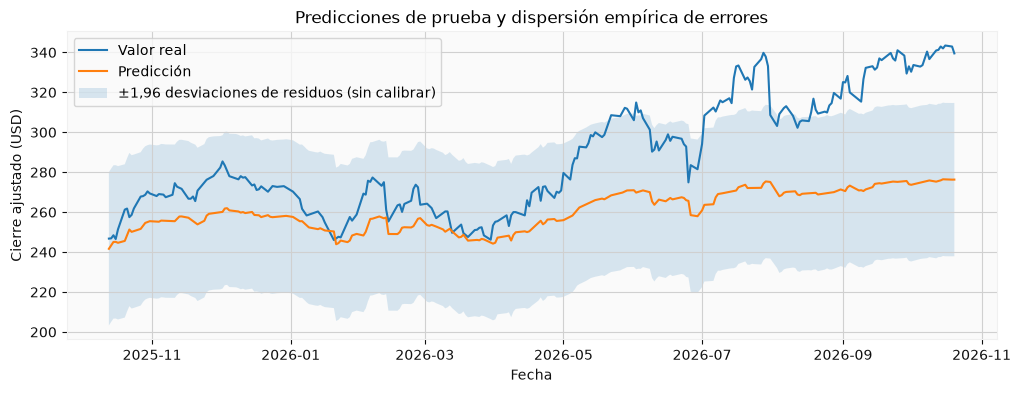

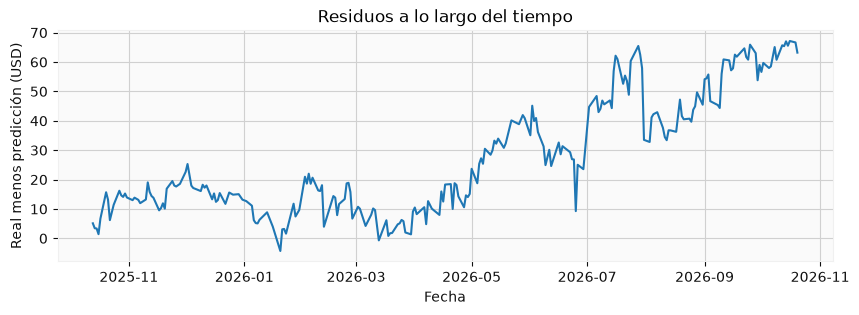

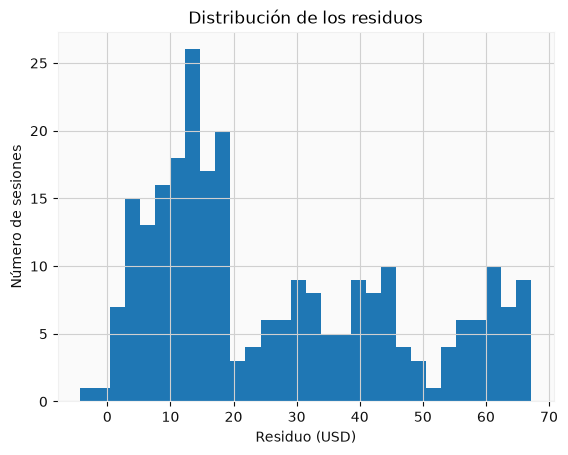

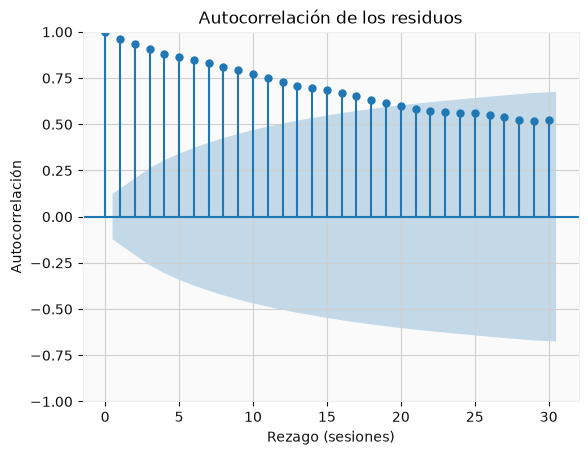

In [8]:
# El mejor modelo recurrente se elige únicamente por el RMSE de validación.
best = min(experiments, key=lambda result: result[6]["RMSE"])
name, score, history, ids, actual, pred, validation_scores = best

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, experiment in zip(axes.ravel(), experiments):
    h = np.array(experiment[2])
    ax.plot(h[:, 0], label="Pérdida de entrenamiento")
    ax.plot(h[:, 1], label="Pérdida de validación")
    ax.set_title(experiment[0])
    ax.set_xlabel("Época")
    ax.set_ylabel("Pérdida MSE normalizada")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, experiment in zip(axes.ravel(), experiments):
    h = np.array(experiment[2])
    ax.plot(h[:, 2], label="RMSE de validación (USD)")
    ax.set_title(experiment[0])
    ax.set_xlabel("Época")
    ax.set_ylabel("USD")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index[ids], actual, label="Valor real")
ax.plot(df.index[ids], pred, label="Predicción")
ax.set_title("Prueba: " + name)
ax.set_xlabel("Fecha")
ax.set_ylabel("Cierre ajustado (USD)")
ax.legend()
plt.show()

res = actual - pred
spread = 1.96 * np.std(res, ddof=1)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index[ids], actual, label="Valor real")
ax.plot(df.index[ids], pred, label="Predicción")
ax.fill_between(
    df.index[ids],
    pred - spread,
    pred + spread,
    alpha=0.16,
    label="±1,96 desviaciones de residuos (sin calibrar)",
)
ax.set_title("Predicciones de prueba y dispersión empírica de errores")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cierre ajustado (USD)")
ax.legend()
plt.show()

pd.DataFrame({
    "Fecha": df.index[ids],
    "Real": actual,
    "Predicción": pred,
    "Residuo": res,
}).to_csv("reports/test_predictions.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(df.index[ids], res)
ax.set_title("Residuos a lo largo del tiempo")
ax.set_xlabel("Fecha")
ax.set_ylabel("Real menos predicción (USD)")
plt.show()

plt.hist(res, bins=30)
plt.title("Distribución de los residuos")
plt.xlabel("Residuo (USD)")
plt.ylabel("Número de sesiones")
plt.show()

plot_acf(res, lags=min(30, len(res) // 3))
plt.title("Autocorrelación de los residuos")
plt.xlabel("Rezago (sesiones)")
plt.ylabel("Autocorrelación")
plt.show()

## 8. Esquema de validación con origen móvil

El esquema representa cómo se amplía el historial disponible para entrenar y se desplaza el periodo posterior de validación. Esta figura es ilustrativa; el **reentrenamiento real** de una LSTM por partición temporal se ejecuta en la sección 10.

La separación final de prueba no se utiliza durante este procedimiento.

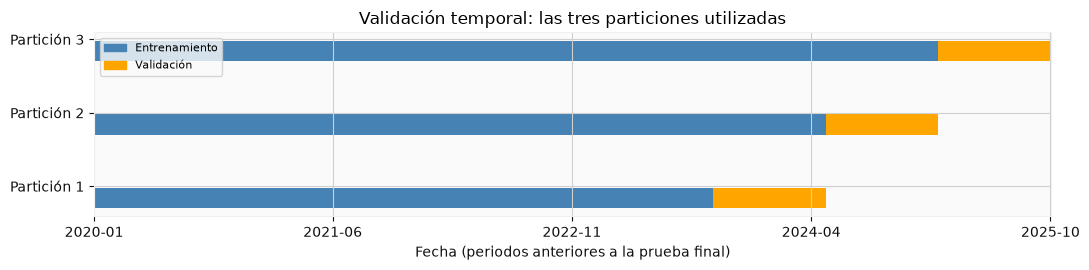

In [9]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(11, 2.8))
fold_edges = np.linspace(int(len(df) * 0.55), b, 4, dtype=int)

for i in range(3):
    train_end = int(fold_edges[i])
    valid_end = int(fold_edges[i + 1])
    ax.broken_barh([(0, train_end)], (i - 0.3, 0.28), facecolors="steelblue")
    ax.broken_barh(
        [(train_end, valid_end - train_end)],
        (i - 0.3, 0.28),
        facecolors="orange",
    )

ax.set_yticks(range(3), [f"Partición {i + 1}" for i in range(3)])
tick_idx = np.linspace(0, b - 1, 5, dtype=int)
ax.set_xticks(tick_idx, [df.index[t].strftime("%Y-%m") for t in tick_idx])
ax.set_xlim(0, b)
ax.set_xlabel("Fecha (periodos anteriores a la prueba final)")
ax.set_title("Validación temporal: las tres particiones utilizadas")
ax.legend(
    handles=[
        Patch(color="steelblue", label="Entrenamiento"),
        Patch(color="orange", label="Validación"),
    ],
    loc="upper left",
    fontsize=8,
)
plt.tight_layout()
plt.show()

## 9. Recuperación de pesos y predicción posterior

Los mejores parámetros de cada modelo se guardan en archivos `.pt`, junto con la información necesaria para aplicar la misma estandarización. En esta sección se vuelve a cargar un modelo y se calcula una estimación empleando las últimas **60 sesiones observadas**, tal como exige la práctica.

La cifra estimada depende de la fecha final del conjunto de datos y no debe confundirse con un precio observado ni con una señal de compra o venta.

In [10]:
def reload_and_forecast(checkpoint_path, history_df):
    """Recupera una red entrenada y estima el siguiente cierre."""
    obj = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    features = obj["features"]

    model = ForecastNet(obj["kind"], len(features))
    model.load_state_dict(obj["state_dict"])
    model.eval()

    x = history_df[features].tail(obj["lookback"]).to_numpy(dtype="float32")
    if len(x) != obj["lookback"]:
        raise ValueError("Historial insuficiente para esta ventana")

    # La conversión explícita a float32 evita errores de tipos en PyTorch.
    x = (
        (x - np.array(obj["scaler_x_mean"], dtype="float32"))
        / np.array(obj["scaler_x_scale"], dtype="float32")
    ).astype("float32")

    with torch.no_grad():
        scaled = model(torch.tensor(x[None, :, :], dtype=torch.float32)).item()

    return scaled * obj["scaler_y_scale"][0] + obj["scaler_y_mean"][0]


selected_forecast = reload_and_forecast("checkpoints/" + name + ".pt", df)
best_60 = min(
    (result for result in experiments if result[0].endswith("_L60")),
    key=lambda result: result[6]["RMSE"],
)
forecast_60 = reload_and_forecast(
    "checkpoints/" + best_60[0] + ".pt", df.tail(60)
)
assert np.isfinite(selected_forecast) and np.isfinite(forecast_60)

print("Estimación del siguiente cierre (modelo seleccionado):", selected_forecast)
print("Comprobación de recarga con 60 sesiones:", best_60[0], forecast_60)

Estimación del siguiente cierre (modelo seleccionado): 276.2652246423209
Comprobación de recarga con 60 sesiones: RNN_6features_L60 276.2652246423209


## 10. Validación temporal mediante reentrenamientos sucesivos

Como comprobación adicional se entrena una LSTM univariada en **tres particiones temporales**. Cada partición utiliza un historial de entrenamiento creciente y evalúa un tramo de validación posterior.

Se registra MAE, RMSE y MAPE para cada tramo y se resume su variación. Estos errores ayudan a valorar la estabilidad temporal del procedimiento; **no sustituyen** la evaluación independiente del conjunto final de prueba.

In [11]:
def walk_forward_lstm(folds=3, epochs=12):
    """Evalúa una LSTM con entrenamiento expansivo y validación posterior."""
    all_metrics = []
    edges = np.linspace(int(len(df) * 0.55), b, folds + 1, dtype=int)

    for k in range(folds):
        train_end = int(edges[k])
        valid_end = int(edges[k + 1])
        if valid_end <= train_end:
            continue

        close = df[["Close"]].to_numpy(dtype="float32")
        scaler = StandardScaler().fit(close[:train_end])
        scaled = scaler.transform(close).ravel()

        xx = np.stack([
            scaled[t - LOOKBACK:t] for t in range(LOOKBACK, valid_end)
        ]).astype("float32")[:, :, None]
        yy = scaled[LOOKBACK:valid_end].astype("float32")
        ids = np.arange(LOOKBACK, valid_end)
        tr = ids < train_end
        va = (ids >= train_end) & (ids < valid_end)

        model = ForecastNet("LSTM", 1).to(DEVICE)
        optim = torch.optim.Adam(model.parameters(), lr=0.001)
        train_loader = DataLoader(
            SlidingWindowDataset(xx[tr], yy[tr]),
            batch_size=64,
            shuffle=True,
        )

        for _ in range(epochs):
            model.train()
            for xbatch, ybatch in train_loader:
                xbatch, ybatch = xbatch.to(DEVICE), ybatch.to(DEVICE)
                optim.zero_grad()
                loss = nn.functional.mse_loss(model(xbatch), ybatch)
                loss.backward()
                optim.step()

        model.eval()
        with torch.no_grad():
            scaled_pred = model(torch.tensor(xx[va], device=DEVICE)).cpu().numpy()

        pred = scaler.inverse_transform(scaled_pred.reshape(-1, 1)).ravel()
        truth = close[ids[va], 0]
        row = {
            "fold": k + 1,
            "train_end": str(df.index[train_end - 1].date()),
            "validation_end": str(df.index[valid_end - 1].date()),
            **metrics(truth, pred),
        }
        all_metrics.append(row)

    return pd.DataFrame(all_metrics)


walk_forward_results = walk_forward_lstm()
display(walk_forward_results.rename(columns={
    "fold": "Partición",
    "train_end": "Fin de entrenamiento",
    "validation_end": "Fin de validación",
}))
display(walk_forward_results[["MAE", "RMSE", "MAPE%"]].agg(["mean", "std"]))

,Partición,Fin de entrenamiento,Fin de validación,MAE,RMSE,MAPE%
0,1,2023-09-25,2024-05-30,3.691982,4.499533,2.046785
1,2,2024-05-30,2025-02-05,22.783392,24.602196,9.910366
2,3,2025-02-05,2025-10-10,6.677693,9.291087,3.075094


,MAE,RMSE,MAPE%
mean,11.051022,12.797606,5.010748
std,10.269615,10.500049,4.274230


## 11. Interpretación y limitaciones

En la prueba final el pronóstico basado en el último cierre resultó más preciso que la red recurrente elegida. No se reemplazó ese resultado por otra arquitectura elegida mirando la prueba, porque hacerlo quitaría sentido a la comparación. La diferencia entre validación y prueba sugiere que el comportamiento del precio cambió entre periodos.

Este cuaderno conserva los resultados, la muestra utilizada, las versiones del entorno y los pesos aprendidos. La semilla aleatoria es **42**; repetir el experimento en otro equipo o con otras versiones puede producir pequeñas diferencias numéricas.

## 12. Resumen ejecutivo de los resultados

El texto siguiente toma las métricas directamente de las celdas anteriores. Resume qué modelo se eligió, qué error obtuvo en la prueba final y cómo se compara con los dos métodos de referencia.

Es la síntesis recomendada para acompañar la entrega; las tablas y gráficas de las secciones anteriores permiten verificar cada afirmación.

In [12]:
from IPython.display import Markdown, display
import platform

baseline_best = baseline_results.sort_values("RMSE").iloc[0]
wfmean = walk_forward_results[["MAE", "RMSE", "MAPE%"]].mean(numeric_only=True)
comparison = "superó" if score["RMSE"] < baseline_best["RMSE"] else "no superó"

summary = f"""# Resumen ejecutivo: predicción del cierre de Apple

El objetivo fue estimar el cierre de AAPL para el día bursátil siguiente y comprobar
si las redes recurrentes ofrecen una ventaja frente a dos referencias sencillas:
repetir el último cierre y usar el promedio de los 20 anteriores.

Se utilizaron datos diarios de Yahoo Finance desde {df.index.min().date()} hasta
{df.index.max().date()} ({len(df)} sesiones después de preparar los indicadores).
Los datos se separaron en orden cronológico: 70 % para entrenar, 15 % para validar
y 15 % para la prueba final. La normalización se ajustó solo con entrenamiento.
Se probaron RNN, LSTM y GRU, con entradas de una y seis variables. El modelo
recurrente se eligió por su RMSE de validación, sin consultar la prueba final.

La elección fue **{name}**, con RMSE de validación de
**{best[6]['RMSE']:.3f} USD**. En prueba obtuvo MAE de **{score['MAE']:.3f} USD**,
RMSE de **{score['RMSE']:.3f} USD** y MAPE de **{score['MAPE%']:.2f} %**.
La referencia más precisa fue **{baseline_best['model']}**
(RMSE de **{baseline_best['RMSE']:.3f} USD**). Por tanto, la red seleccionada
**{comparison}** a la referencia sencilla. La diferencia entre validación y
prueba indica que su rendimiento no se mantuvo en el periodo posterior.

La LSTM evaluada en tres particiones temporales obtuvo un RMSE medio de
validación de **{wfmean['RMSE']:.3f} USD**. También se comprobaron la recuperación
de los pesos guardados y una estimación con las últimas 60 sesiones: **{forecast_60:.2f} USD**.
Esa cifra es una salida del modelo, no un precio confirmado ni una recomendación
de inversión.

La comparación es válida para esta muestra, no para todos los periodos del
mercado. Cambios de régimen y volatilidad pueden alterar el error; además,
la franja alrededor de las predicciones describe residuos observados y no
constituye un intervalo de confianza calibrado. La semilla utilizada fue 42.
"""

with open("reports/executive_summary.md", "w", encoding="utf-8") as output:
    output.write(summary)
display(Markdown(summary))

with open("reports/environment.txt", "w", encoding="utf-8") as output:
    output.write(
        f"Python: {platform.python_version()}\n"
        f"PyTorch: {torch.__version__}\n"
        f"CUDA: {torch.version.cuda}\n"
        f"cuDNN: {torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else 'no disponible'}\n"
        f"Dispositivo: {DEVICE}\n"
        f"NumPy: {np.__version__}\n"
        f"Pandas: {pd.__version__}\n"
    )


# Resumen ejecutivo: predicción del cierre de Apple

El objetivo fue estimar el cierre de AAPL para el día bursátil siguiente y comprobar
si las redes recurrentes ofrecen una ventaja frente a dos referencias sencillas:
repetir el último cierre y usar el promedio de los 20 anteriores.

Se utilizaron datos diarios de Yahoo Finance desde 2020-01-02 hasta
2026-10-20 (1709 sesiones después de preparar los indicadores).
Los datos se separaron en orden cronológico: 70 % para entrenar, 15 % para validar
y 15 % para la prueba final. La normalización se ajustó solo con entrenamiento.
Se probaron RNN, LSTM y GRU, con entradas de una y seis variables. El modelo
recurrente se eligió por su RMSE de validación, sin consultar la prueba final.

La elección fue **RNN_6features_L60**, con RMSE de validación de
**5.673 USD**. En prueba obtuvo MAE de **27.013 USD**,
RMSE de **33.314 USD** y MAPE de **8.83 %**.
La referencia más precisa fue **Último cierre observado**
(RMSE de **4.440 USD**). Por tanto, la red seleccionada
**no superó** a la referencia sencilla. La diferencia entre validación y
prueba indica que su rendimiento no se mantuvo en el periodo posterior.

La LSTM evaluada en tres particiones temporales obtuvo un RMSE medio de
validación de **12.798 USD**. También se comprobaron la recuperación
de los pesos guardados y una estimación con las últimas 60 sesiones: **276.27 USD**.
Esa cifra es una salida del modelo, no un precio confirmado ni una recomendación
de inversión.

La comparación es válida para esta muestra, no para todos los periodos del
mercado. Cambios de régimen y volatilidad pueden alterar el error; además,
la franja alrededor de las predicciones describe residuos observados y no
constituye un intervalo de confianza calibrado. La semilla utilizada fue 42.
